# Modelo de predicción de no afiliación a salud

En este notebook entrenamos un modelo supervisado que predice si una persona de la encuesta ASP 2022 **no tiene afiliación al sistema de salud**, a partir de sus características sociodemográficas y de la localidad donde vive. Los pasos son:

- Preparar la variable objetivo y las variables de entrada
- Entrenar una regresión logística como línea base
- Entrenar modelos de ensamble (Random Forest y Gradient Boosting)
- Optimizar hiperparámetros con validación cruzada
- Evaluar el mejor modelo con datos que no vio
- Interpretar el modelo con SHAP
- Guardar el modelo para el endpoint de AWS

In [30]:
#importar librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from scipy.stats import randint, uniform
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (roc_auc_score, f1_score, recall_score, precision_score,
                             accuracy_score, ConfusionMatrixDisplay, RocCurveDisplay)
import shap
from sklearn.base import clone
import math

In [2]:
#cargamos el dataset limpio (el mismo que usamos para el clustering)
df = pd.read_csv("../data/processed/asp_2022_variables_limpio.csv")
print("Filas y columnas:", df.shape)

df["afiliado_seg_social_salud"].value_counts()

Filas y columnas: (3003, 50)


afiliado_seg_social_salud
Sí                     1499
No                     1492
No sabe/No responde      12
Name: count, dtype: int64

# Variable objetivo

La propuesta planteaba tres clases (afiliado / no afiliado / desconocido), pero "No sabe/No responde" son solo 12 personas (0,4 %): no alcanza para que un modelo aprenda esa clase. Por eso la dejamos **binaria**:

- **1 = NO afiliada** (es lo que queremos detectar)
- **0 = afiliada**

y quitamos las 12 personas sin respuesta. Las clases quedan **balanceadas** (casi 50 % y 50 %), así que no hace falta remuestreo.

In [3]:
#quitamos a quienes no saben o no respondieron
df = df[df["afiliado_seg_social_salud"] != "No sabe/No responde"].reset_index(drop=True)

#variable objetivo: 1 = NO afiliada, 0 = afiliada
y = (df["afiliado_seg_social_salud"] == "No").astype(int)

print("Personas:", len(df))
print("Proporción de NO afiliadas: %0.3f" % y.mean())

Personas: 2991
Proporción de NO afiliadas: 0.499


# Variables de entrada

Usamos **las mismas 18 variables del clustering** con la misma transformación, para que el modelo y los perfiles hablen el mismo idioma. Para no copiar los diccionarios a mano, los leemos del archivo `clustering_config.json` que guardamos en el notebook de minería.

Además agregamos **3 indicadores de la localidad** (de SaluData) que pide la propuesta: pobreza monetaria 2021, coeficiente de Gini 2021 y % de afiliados al régimen subsidiado en 2022.

**Variables que NO entran (fuga de información):** `regimen_salud`, las preguntas de barreras en salud, `atencion_medica_ult_anio` y similares. Solo se les preguntaron a quienes están afiliadas o dependen de estar afiliada: si las usamos, el modelo "haría trampa" con información que ya revela la respuesta.

**Tampoco usamos `cluster` como variable:** se calcula con las mismas 18 variables, así que no aporta información nueva.

In [4]:
#diccionarios de recodificación guardados en el notebook de minería
with open("modelos/clustering_config.json", encoding="utf-8") as archivo:
    config = json.load(archivo)

variables = config["variables"]   #las 18 variables, en el mismo orden del clustering
print(variables)

['edad', 'personas_hogar', 'dependientes_economicos', 'autopercepcion_nivel_economico', 'horas_semana_asp', 'edad_inicio_asp', 'tiempo_viviendo_bogota', 'nivel_educativo', 'tipo_vivienda', 'migrante', 'grupo_etnico', 'victima_conflicto_armado', 'ingresos_insuficientes', 'paga_intermediario_tercero', 'discriminacion_general', 'amenazas_recibidas', 'forzada_relaciones_sexuales', 'violencia_fuerza_publica']


In [5]:
#tomamos las columnas originales del CSV
columnas_originales = ["edad", "personas_hogar", "dependientes_economicos", "autopercepcion_nivel_economico",
                       "horas_semana_asp", "edad_inicio_asp", "tiempo_viviendo_bogota", "nivel_educativo",
                       "tipo_vivienda", "pais_nacimiento", "autoreconocimiento_etnico", "victima_conflicto_armado",
                       "ingresos_suficientes_gastos", "paga_intermediario_tercero", "discriminacion_general",
                       "amenazas_recibidas", "forzada_relaciones_sexuales", "violencia_fuerza_publica"]
X = df[columnas_originales].copy()

#"No sabe/No responde" -> moda (igual que en minería)
for col in X.columns:
    if X[col].dtype != "int64" and X[col].dtype != "float64":
        moda = X[col][X[col] != "No sabe/No responde"].mode()[0]
        X[col] = X[col].replace("No sabe/No responde", moda)

#ordinales con los diccionarios del JSON
for col, diccionario in config["recodificacion"].items():
    X[col] = X[col].map(diccionario)

#binarias a 1 y 0
X["pais_nacimiento"] = (X["pais_nacimiento"] != "Colombia").astype(int)
X["autoreconocimiento_etnico"] = (X["autoreconocimiento_etnico"] != "Ninguno").astype(int)
X["ingresos_suficientes_gastos"] = (X["ingresos_suficientes_gastos"] == "No").astype(int)
for col in ["victima_conflicto_armado", "paga_intermediario_tercero", "discriminacion_general",
            "amenazas_recibidas", "forzada_relaciones_sexuales", "violencia_fuerza_publica"]:
    X[col] = (X[col] == "Sí").astype(int)

X = X.rename(columns={"pais_nacimiento": "migrante",
                      "autoreconocimiento_etnico": "grupo_etnico",
                      "ingresos_suficientes_gastos": "ingresos_insuficientes"})

#comprobamos que quedaron igual que en el clustering
print("Mismas variables y orden que el clustering:", list(X.columns) == variables)

Mismas variables y orden que el clustering: True


In [6]:
#indicadores de la localidad (un valor por localidad) desde la base integrada con SaluData
indicadores = pd.read_csv("../data/processed/asp_2022_saludata_integrado.csv")
indicadores = indicadores[["localidad", "pobreza_monetaria_pct_2021", "gini_2021",
                           "subsidiado_pct_propio_2022"]].drop_duplicates()
print("Localidades con indicadores:", len(indicadores))

#pegamos los indicadores a cada persona según su localidad
X["localidad"] = df["localidad"]
X = X.merge(indicadores, on="localidad", how="left").drop(columns="localidad")

print("Valores vacíos:", X.isnull().sum().sum())
print("Filas y columnas de X:", X.shape)
X.head()

Localidades con indicadores: 19
Valores vacíos: 0
Filas y columnas de X: (2991, 21)


,edad,personas_hogar,dependientes_economicos,autopercepcion_nivel_economico,horas_semana_asp,edad_inicio_asp,tiempo_viviendo_bogota,nivel_educativo,tipo_vivienda,migrante,...,victima_conflicto_armado,ingresos_insuficientes,paga_intermediario_tercero,discriminacion_general,amenazas_recibidas,forzada_relaciones_sexuales,violencia_fuerza_publica,pobreza_monetaria_pct_2021,gini_2021,subsidiado_pct_propio_2022
0,19,1,0,5,48,18,0,4,0,0,...,0,1,1,0,0,0,0,23.94,0.46,14.39
1,26,1,2,4,48,26,1,5,1,1,...,0,1,1,0,0,0,0,23.94,0.46,14.39
2,21,7,4,5,48,21,1,2,0,1,...,0,1,1,0,1,1,1,23.94,0.46,14.39
3,20,2,0,1,42,16,0,3,2,0,...,0,0,0,0,0,0,0,23.94,0.46,14.39
4,20,1,4,1,56,16,0,2,2,1,...,0,1,0,0,0,0,0,23.94,0.46,14.39


# Separación en entrenamiento y prueba

Separamos el **20 % de las personas como conjunto de prueba** y no lo tocamos hasta el final: es como un examen con preguntas que el modelo nunca vio. Con el 80 % restante entrenamos y comparamos modelos usando validación cruzada.

Usamos `stratify=y` para que ambos conjuntos tengan la misma proporción de personas no afiliadas.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    stratify=y, random_state=42)

print("Entrenamiento:", X_train.shape, " Proporción NO afiliadas: %0.3f" % y_train.mean())
print("Prueba:       ", X_test.shape, " Proporción NO afiliadas: %0.3f" % y_test.mean())

Entrenamiento: (2392, 21)  Proporción NO afiliadas: 0.499
Prueba:        (599, 21)  Proporción NO afiliadas: 0.499


# Línea base: regresión logística

La regresión logística estima la **probabilidad de no estar afiliada** combinando las variables con un peso (coeficiente) cada una. Es simple e interpretable, por eso la usamos como punto de comparación.

**Validación cruzada (5 folds):** dividimos el conjunto de entrenamiento en 5 partes; entrenamos con 4 y evaluamos con la que queda, rotando 5 veces. Así cada resultado se mide con datos que el modelo no vio, y el promedio es más confiable que una sola división.

**Métricas** (para la clase 1 = NO afiliada):

- **AUC**: qué tan bien ordena a las personas de mayor a menor riesgo. 0,5 = al azar, 1 = perfecto. Es la métrica principal.
- **Recall**: de todas las personas que **realmente** no están afiliadas, qué porcentaje detecta el modelo.
- **Precisión**: de las personas que el modelo **marca** como no afiliadas, qué porcentaje realmente lo es.
- **F1**: combina recall y precisión en un solo número.
- **Exactitud (accuracy)**: porcentaje total de aciertos. Como las clases están balanceadas sí es interpretable, pero no es la principal.

In [8]:
#validación cruzada estratificada: 5 partes con la misma proporción de no afiliadas
validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#métricas que vamos a calcular en cada parte
metricas = ["roc_auc", "f1", "recall", "precision", "accuracy"]

#pipeline: primero escalar, después la regresión logística
modelo_logistico = Pipeline([
    ("escalador", StandardScaler()),
    ("logistica", LogisticRegression(max_iter=1000))
])

In [9]:
#entrenamos y evaluamos 5 veces
resultados_log = cross_validate(modelo_logistico, X_train, y_train,
                                cv=validacion, scoring=metricas)

#tabla con el resultado de cada parte
tabla_log = pd.DataFrame({m: resultados_log["test_" + m] for m in metricas})
tabla_log.index = ["Parte " + str(i + 1) for i in range(5)]

print("Promedio:\n", tabla_log.mean().round(3))
print("\nDesviación estándar:\n", tabla_log.std().round(3))
tabla_log.round(3)

Promedio:
 roc_auc      0.855
f1           0.808
recall       0.757
precision    0.867
accuracy     0.821
dtype: float64

Desviación estándar:
 roc_auc      0.025
f1           0.028
recall       0.034
precision    0.034
accuracy     0.026
dtype: float64


,roc_auc,f1,recall,precision,accuracy
Parte 1,0.864,0.817,0.757,0.887,0.831
Parte 2,0.827,0.772,0.715,0.838,0.789
Parte 3,0.831,0.793,0.765,0.824,0.801
Parte 4,0.885,0.846,0.807,0.889,0.854
Parte 5,0.867,0.812,0.741,0.898,0.828


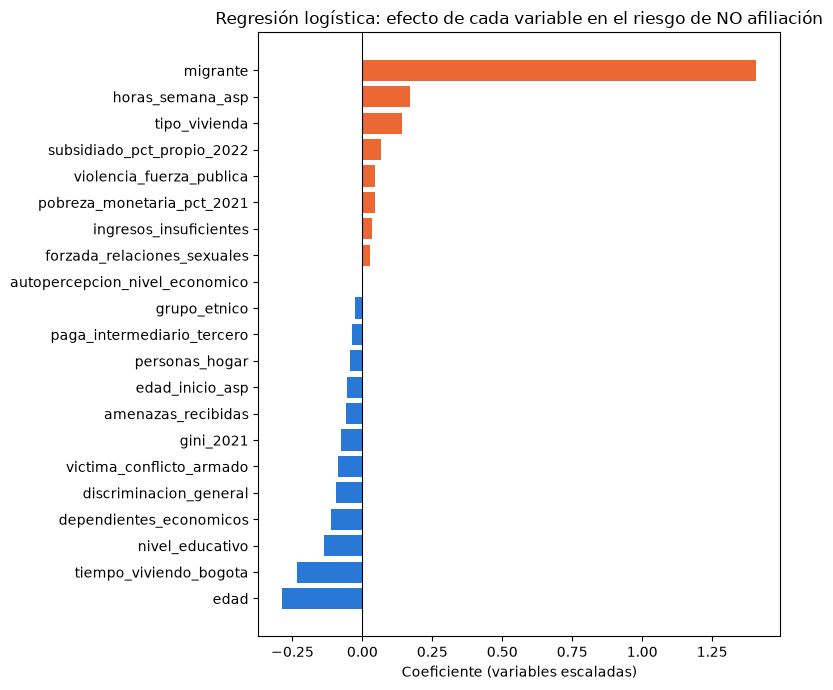

In [10]:
#entrenamos con todo el conjunto de entrenamiento para ver los coeficientes
modelo_logistico.fit(X_train, y_train)

coeficientes = pd.Series(modelo_logistico.named_steps["logistica"].coef_[0],
                         index=X_train.columns).sort_values()

#gráfica: positivo = aumenta el riesgo de NO estar afiliada, negativo = lo disminuye
plt.figure(figsize=(8, 7), dpi=100)
colores_coef = ["#eb6834" if c > 0 else "#2a78d6" for c in coeficientes]
plt.barh(coeficientes.index, coeficientes.values, color=colores_coef)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coeficiente (variables escaladas)")
plt.title("Regresión logística: efecto de cada variable en el riesgo de NO afiliación")
plt.tight_layout()
plt.show()

**Resultados de la línea base** (validación cruzada, 5 partes):

- **AUC = 0,855**: el modelo ordena bien a las personas según su riesgo.
- **Precisión = 0,87** y **recall = 0,76**: cuando el modelo marca a alguien como no afiliada casi siempre acierta, pero **deja sin detectar a cerca de 1 de cada 4** personas no afiliadas. Para una herramienta de focalización de política pública, ese recall es lo que más conviene mejorar.

**Coeficientes:** el factor que más pesa, por mucho, es **ser migrante** (coeficiente 1,41, cinco veces más que el siguiente). Le siguen la **edad** y el **tiempo viviendo en Bogotá**: las personas más jóvenes y recién llegadas tienen más riesgo. Los indicadores de localidad tienen coeficientes muy pequeños.

Esto coincide con los perfiles del clustering: el perfil "Migrantes de llegada reciente" es el de menor afiliación.

# Modelos de ensamble

Un **ensamble** combina muchos modelos simples (árboles de decisión) para obtener uno más fuerte. Probamos dos tipos:

- **Random Forest**: entrena cientos de árboles **en paralelo**, cada uno con una muestra al azar de personas y de variables, y al final **vota**. Al promediar muchos árboles distintos se reduce el sobreajuste.
- **Gradient Boosting**: entrena árboles **uno detrás de otro**; cada árbol nuevo se concentra en corregir los errores de los anteriores.

A diferencia de la regresión logística, los árboles **no necesitan escalado** (solo comparan si un valor es mayor o menor que un umbral) y pueden captar **interacciones** entre variables, por ejemplo que el efecto de ser migrante dependa del tiempo en Bogotá.

Por ahora usamos hiperparámetros razonables; en la siguiente sección los optimizamos.

In [11]:
#los tres modelos que vamos a comparar
modelos = {
    "Regresión logística": modelo_logistico,
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

In [12]:
#evaluamos los tres modelos con la MISMA validación cruzada
resultados = {}
for nombre, modelo in modelos.items():
    resultados[nombre] = cross_validate(modelo, X_train, y_train,
                                        cv=validacion, scoring=metricas)
    print(nombre, "listo")

#tabla comparativa con el promedio de cada métrica
comparacion = pd.DataFrame({nombre: {m: r["test_" + m].mean() for m in metricas}
                            for nombre, r in resultados.items()}).T
comparacion.round(3)

Regresión logística listo
Random Forest listo
Gradient Boosting listo


,roc_auc,f1,recall,precision,accuracy
Regresión logística,0.855,0.808,0.757,0.867,0.821
Random Forest,0.872,0.811,0.762,0.868,0.823
Gradient Boosting,0.861,0.804,0.764,0.851,0.814


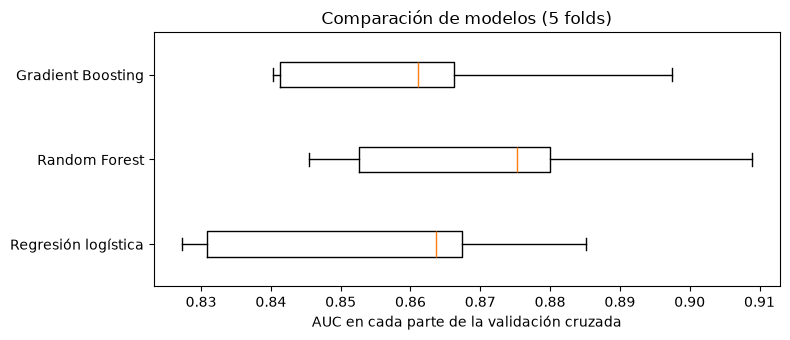

In [13]:
#AUC de cada parte de la validación, por modelo
plt.figure(figsize=(8, 3.5), dpi=100)
plt.boxplot([r["test_roc_auc"] for r in resultados.values()],
            orientation="horizontal", tick_labels=list(resultados.keys()))
plt.xlabel("AUC en cada parte de la validación cruzada")
plt.title("Comparación de modelos (5 folds)")
plt.tight_layout()
plt.show()

**Comparación (validación cruzada, 5 partes):**

- **Random Forest** tiene el mejor AUC (**0,873**), seguido de Gradient Boosting (0,861) y la regresión logística (0,855).
- La mejora sobre la línea base es **pequeña** (+0,018 de AUC) y en F1, recall y precisión los tres modelos quedan casi iguales.
- El **recall sigue cerca de 0,76** en los tres: todos dejan sin detectar a cerca de 1 de cada 4 personas no afiliadas.

Interpretación: la mayor parte de la señal está en pocas variables (sobre todo la condición migratoria), y eso lo capta bien hasta un modelo lineal. Los ensambles agregan un poco al captar interacciones. Pasamos **Random Forest** a la optimización de hiperparámetros por tener el mejor AUC, y también optimizamos Gradient Boosting para confirmar.

# Optimización de hiperparámetros

Los **hiperparámetros** son decisiones que tomamos antes de entrenar (cuántos árboles, qué tan profundos, cuántas personas mínimo por hoja). Para elegirlos probamos varias combinaciones con la misma validación cruzada y nos quedamos con la de mejor AUC. Usamos las dos estrategias de la propuesta:

- **Grid Search** (Random Forest): prueba **todas** las combinaciones de una cuadrícula. Es exhaustivo, pero el número de pruebas crece muy rápido.
- **Random Search** (Gradient Boosting): prueba un número fijo de combinaciones **al azar** dentro de unos rangos. Explora más valores con menos pruebas; conviene cuando hay muchos hiperparámetros.

In [14]:
#cuadrícula de hiperparámetros para Random Forest (4 x 4 x 2 = 32 combinaciones)
grid_rf = {
    "max_depth": [None, 5, 10, 20],        #profundidad máxima de cada árbol (None = sin límite)
    "min_samples_leaf": [1, 5, 10, 20],    #mínimo de personas en cada hoja
    "max_features": ["sqrt", 0.5]          #cuántas variables mira cada división
}

busqueda_rf = GridSearchCV(
    RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    grid_rf, cv=validacion, scoring="roc_auc", n_jobs=-1)
busqueda_rf.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda_rf.best_params_)
print("Mejor AUC (validación cruzada): %0.3f" % busqueda_rf.best_score_)

/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.

Mejores hiperparámetros: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5}
Mejor AUC (validación cruzada): 0.872


In [15]:
#las 5 mejores combinaciones
top_rf = pd.DataFrame(busqueda_rf.cv_results_).sort_values("rank_test_score")
top_rf[["params", "mean_test_score", "std_test_score"]].head(5).round(4)

,params,mean_test_score,std_test_score
1,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.8724,0.0224
25,"{'max_depth': 20, 'max_features': 'sqrt', 'min...",0.8724,0.0224
21,"{'max_depth': 10, 'max_features': 0.5, 'min_sa...",0.8710,0.0199
17,"{'max_depth': 10, 'max_features': 'sqrt', 'min...",0.8709,0.0223
18,"{'max_depth': 10, 'max_features': 'sqrt', 'min...",0.8707,0.0242


In [16]:
#rangos de valores para Gradient Boosting (se eligen al azar dentro de ellos)
distribuciones_gb = {
    "n_estimators": randint(100, 500),         #número de árboles: entero entre 100 y 499
    "learning_rate": uniform(0.01, 0.19),      #tasa de aprendizaje: decimal entre 0.01 y 0.20
    "max_depth": [2, 3, 4],                    #profundidad de cada árbol
    "subsample": [0.7, 0.85, 1.0],             #fracción de personas que ve cada árbol
    "min_samples_leaf": [1, 5, 10, 20]
}

busqueda_gb = RandomizedSearchCV(
    GradientBoostingClassifier(random_state=42),
    distribuciones_gb, n_iter=30, cv=validacion,
    scoring="roc_auc", random_state=42, n_jobs=-1)
busqueda_gb.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda_gb.best_params_)
print("Mejor AUC (validación cruzada): %0.3f" % busqueda_gb.best_score_)

Mejores hiperparámetros: {'learning_rate': np.float64(0.02235980266720311), 'max_depth': 2, 'min_samples_leaf': 20, 'n_estimators': 113, 'subsample': 0.85}
Mejor AUC (validación cruzada): 0.867


In [17]:
#evaluamos los modelos optimizados con todas las métricas, con la misma validación
modelos_optimizados = {
    "Regresión logística": modelo_logistico,
    "Random Forest (optimizado)": busqueda_rf.best_estimator_,
    "Gradient Boosting (optimizado)": busqueda_gb.best_estimator_
}

resultados_opt = {}
for nombre, modelo in modelos_optimizados.items():
    resultados_opt[nombre] = cross_validate(modelo, X_train, y_train,
                                            cv=validacion, scoring=metricas)

comparacion_opt = pd.DataFrame({nombre: {m: r["test_" + m].mean() for m in metricas}
                                for nombre, r in resultados_opt.items()}).T
comparacion_opt.round(3)

,roc_auc,f1,recall,precision,accuracy
Regresión logística,0.855,0.808,0.757,0.867,0.821
Random Forest (optimizado),0.872,0.811,0.762,0.868,0.823
Gradient Boosting (optimizado),0.867,0.806,0.750,0.870,0.819


**Resultados de la optimización:**

- **Random Forest:** la mejor combinación fue `max_depth=None`, `max_features="sqrt"`, `min_samples_leaf=5`, que es **la misma que ya usábamos**. Su AUC sigue en ~0,873. Las 5 mejores combinaciones difieren en menos de 0,002 de AUC, mucho menos que la variación entre partes (~0,02): el modelo es **robusto** a sus hiperparámetros.
- **Gradient Boosting:** mejoró de 0,861 a ~0,867 con árboles poco profundos (`max_depth=2`) y una tasa de aprendizaje baja, pero sigue por debajo de Random Forest.

La optimización casi no mejora los modelos: indica que estamos cerca del **límite de información** que tienen estas 21 variables, no de un problema de ajuste del modelo.

**Modelo elegido: Random Forest optimizado**, por tener el mejor AUC. El recall (~0,76) no cambia con los hiperparámetros porque estos optimizan el AUC; lo mejoraremos ajustando el **umbral de decisión** en la evaluación final.

# Evaluación final con el conjunto de prueba

## Elección del umbral de decisión

El modelo no responde "sí" o "no": da una **probabilidad** de no estar afiliada. Por defecto, si la probabilidad es ≥ 0,5 la persona se marca como no afiliada. Pero ese 0,5 es arbitrario.

- **Bajar el umbral** → el modelo marca a más personas: **sube el recall** (detecta a más no afiliadas) pero **baja la precisión** (más falsas alarmas).
- **Subirlo** → lo contrario.

Para una herramienta de **focalización en política pública** es más grave dejar sin detectar a una persona sin salud (falso negativo) que incluir a alguien que sí estaba afiliada (falso positivo): el costo de un falso positivo es verificar su afiliación. Por eso buscamos un umbral con **mejor recall** sin que la precisión caiga demasiado.

**Importante:** el umbral se elige con los datos de **entrenamiento** (con validación cruzada), no con los de prueba. Si lo eligiéramos mirando la prueba, ese examen dejaría de ser "nuevo".

In [18]:
#modelo elegido en la sección anterior
modelo_final = busqueda_rf.best_estimator_

#probabilidad de cada persona de entrenamiento, calculada por un modelo que NO la vio
prob_cv = cross_val_predict(modelo_final, X_train, y_train, cv=validacion,
                            method="predict_proba")[:, 1]

#probamos umbrales entre 0,20 y 0,60
filas = []
for umbral in np.arange(0.20, 0.61, 0.05):
    prediccion = (prob_cv >= umbral).astype(int)
    filas.append({"umbral": round(umbral, 2),
                  "recall": recall_score(y_train, prediccion),
                  "precision": precision_score(y_train, prediccion),
                  "f1": f1_score(y_train, prediccion),
                  "porcentaje_marcadas": prediccion.mean()})

tabla_umbrales = pd.DataFrame(filas)
tabla_umbrales.round(3)

,umbral,recall,precision,f1,porcentaje_marcadas
0,0.20,0.942,0.606,0.738,0.776
1,0.25,0.912,0.670,0.773,0.679
2,0.30,0.863,0.729,0.791,0.590
3,0.35,0.830,0.783,0.806,0.529
4,0.40,0.805,0.822,0.813,0.488
5,0.45,0.778,0.851,0.813,0.456
6,0.50,0.762,0.867,0.811,0.438
7,0.55,0.749,0.873,0.806,0.428
8,0.60,0.733,0.875,0.797,0.418


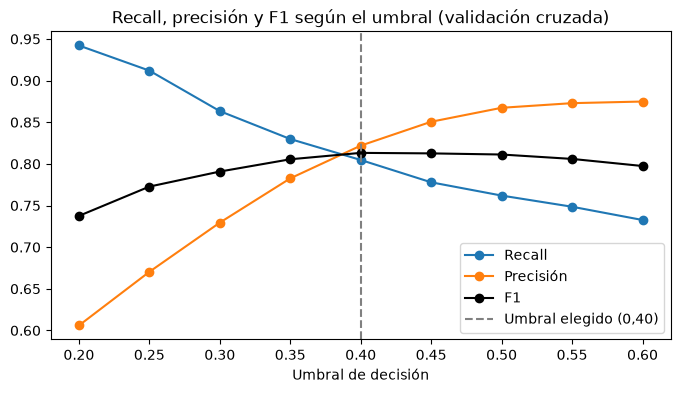

In [19]:
#cómo cambian recall y precisión con el umbral
plt.figure(figsize=(8, 4), dpi=100)
plt.plot(tabla_umbrales["umbral"], tabla_umbrales["recall"], marker="o", label="Recall")
plt.plot(tabla_umbrales["umbral"], tabla_umbrales["precision"], marker="o", label="Precisión")
plt.plot(tabla_umbrales["umbral"], tabla_umbrales["f1"], marker="o", label="F1", color="black")
plt.axvline(0.40, color="gray", linestyle="--", label="Umbral elegido (0,40)")
plt.xlabel("Umbral de decisión")
plt.title("Recall, precisión y F1 según el umbral (validación cruzada)")
plt.legend()
plt.show()

umbral_elegido = 0.40

In [20]:
#AHORA sí usamos los datos de prueba por primera vez
prob_test = modelo_final.predict_proba(X_test)[:, 1]
print("AUC en prueba: %0.3f" % roc_auc_score(y_test, prob_test))

#comparamos el umbral por defecto (0,5) con el elegido
resumen = {}
for umbral in [0.5, umbral_elegido]:
    prediccion = (prob_test >= umbral).astype(int)
    resumen["Umbral " + str(umbral)] = {"recall": recall_score(y_test, prediccion),
                                        "precision": precision_score(y_test, prediccion),
                                        "f1": f1_score(y_test, prediccion),
                                        "accuracy": accuracy_score(y_test, prediccion)}
pd.DataFrame(resumen).round(3)

AUC en prueba: 0.879


,Umbral 0.5,Umbral 0.4
recall,0.766,0.813
precision,0.881,0.827
f1,0.819,0.820
accuracy,0.831,0.821


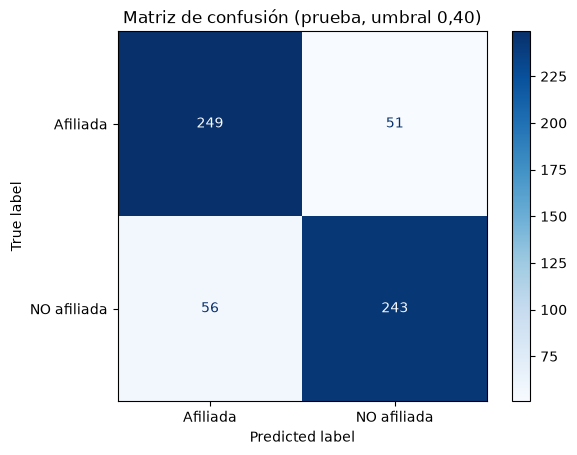

In [21]:
#matriz de confusión con el umbral elegido
prediccion_final = (prob_test >= umbral_elegido).astype(int)

ConfusionMatrixDisplay.from_predictions(y_test, prediccion_final,
                                        display_labels=["Afiliada", "NO afiliada"],
                                        cmap="Blues")
plt.title("Matriz de confusión (prueba, umbral 0,40)")
plt.show()

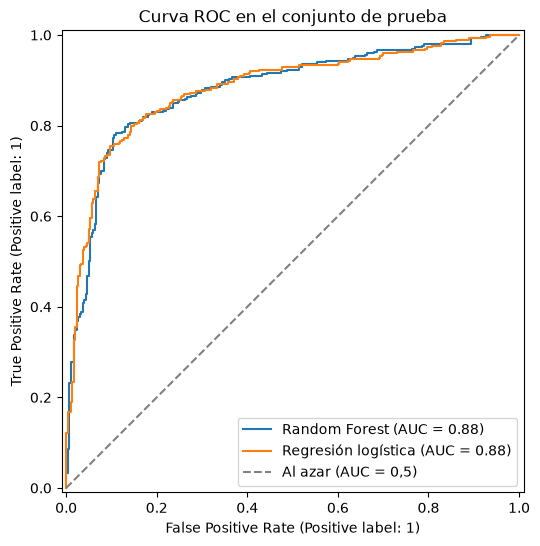

In [22]:
#curva ROC del Random Forest y de la regresión logística en los datos de prueba
modelo_logistico.fit(X_train, y_train)   #nos aseguramos de que esté entrenada con todo X_train

fig, eje = plt.subplots(figsize=(6, 6), dpi=100)
RocCurveDisplay.from_estimator(modelo_final, X_test, y_test, name="Random Forest", ax=eje)
RocCurveDisplay.from_estimator(modelo_logistico, X_test, y_test, name="Regresión logística", ax=eje)
eje.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Al azar (AUC = 0,5)")
eje.set_title("Curva ROC en el conjunto de prueba")
eje.legend()
plt.show()

In [23]:
#bootstrap sobre los datos de prueba: diferencia de AUC entre Random Forest y regresión logística
prob_log = modelo_logistico.predict_proba(X_test)[:, 1]
y_test_arr = y_test.values

generador = np.random.default_rng(42)
diferencias_auc = []
for i in range(1000):
    indices = generador.choice(len(y_test_arr), size=len(y_test_arr), replace=True)
    diferencias_auc.append(roc_auc_score(y_test_arr[indices], prob_test[indices]) -
                           roc_auc_score(y_test_arr[indices], prob_log[indices]))

intervalo = np.percentile(diferencias_auc, [2.5, 97.5])
print("Diferencia promedio de AUC (RF - logística): %0.3f" % np.mean(diferencias_auc))
print("Intervalo de confianza 95 %%: [%0.3f, %0.3f]" % (intervalo[0], intervalo[1]))

Diferencia promedio de AUC (RF - logística): -0.003
Intervalo de confianza 95 %: [-0.016, 0.011]


**Resultados en el conjunto de prueba** (599 personas que los modelos nunca vieron):

- **AUC del Random Forest = 0,879**, muy parecido al de validación cruzada (0,873): el modelo **generaliza bien**, no está sobreajustado.
- **Con el umbral 0,40**: recall 0,81, precisión 0,83 y F1 0,82. Frente al umbral 0,5, detectamos **cerca de 15 personas no afiliadas más** de cada 300, a cambio de unas 18 falsas alarmas más.

**Random Forest vs. regresión logística:** en la prueba, la logística tiene un AUC de 0,882, prácticamente igual. El intervalo de confianza de la diferencia (−0,016 a +0,011) **incluye el cero**: los dos modelos rinden igual.

Esto tiene una consecuencia práctica para el despliegue: si dos modelos rinden igual, conviene el **más simple y más interpretable**. La regresión logística además se puede exportar como unos pocos números (coeficientes), igual que hicimos con el clustering, y ejecutar en la Lambda **sin instalar scikit-learn**. Esta decisión la tomamos en la sección de guardado del modelo.

# Interpretabilidad con SHAP

Un Random Forest combina 300 árboles: no se puede leer directamente como la regresión logística. **SHAP** (SHapley Additive exPlanations) explica cada predicción repartiendo "el mérito" entre las variables:

- Cada persona parte de la **probabilidad promedio** de no afiliación.
- Cada variable **suma o resta** a esa probabilidad según el valor que tenga esa persona. Ese aporte es su **valor SHAP**.
- La suma de todos los aportes da exactamente la predicción del modelo para esa persona.

Así obtenemos dos tipos de explicación:

- **Global**: qué variables pesan más en el modelo en general (promedio de los aportes en valor absoluto).
- **Local**: por qué el modelo le asignó cierto riesgo a **una persona concreta**. Es lo que haría la herramienta transparente y auditable para el sector público que plantea la propuesta.

Calculamos SHAP sobre el conjunto de **prueba**.

In [24]:
#explicador especializado en modelos de árboles (rápido y exacto)
explicador = shap.TreeExplainer(modelo_final)
valores_shap = explicador(X_test)
print("Forma de los valores SHAP:", valores_shap.shape)

#el modelo tiene dos clases; nos quedamos con la clase 1 (NO afiliada)
if len(valores_shap.shape) == 3:
    shap_no_afiliada = valores_shap[:, :, 1]
else:
    shap_no_afiliada = valores_shap

Forma de los valores SHAP: (599, 21, 2)


migrante                      0.199
tiempo_viviendo_bogota        0.090
edad                          0.046
horas_semana_asp              0.016
victima_conflicto_armado      0.014
discriminacion_general        0.012
tipo_vivienda                 0.012
subsidiado_pct_propio_2022    0.011
personas_hogar                0.009
edad_inicio_asp               0.009
dtype: float64


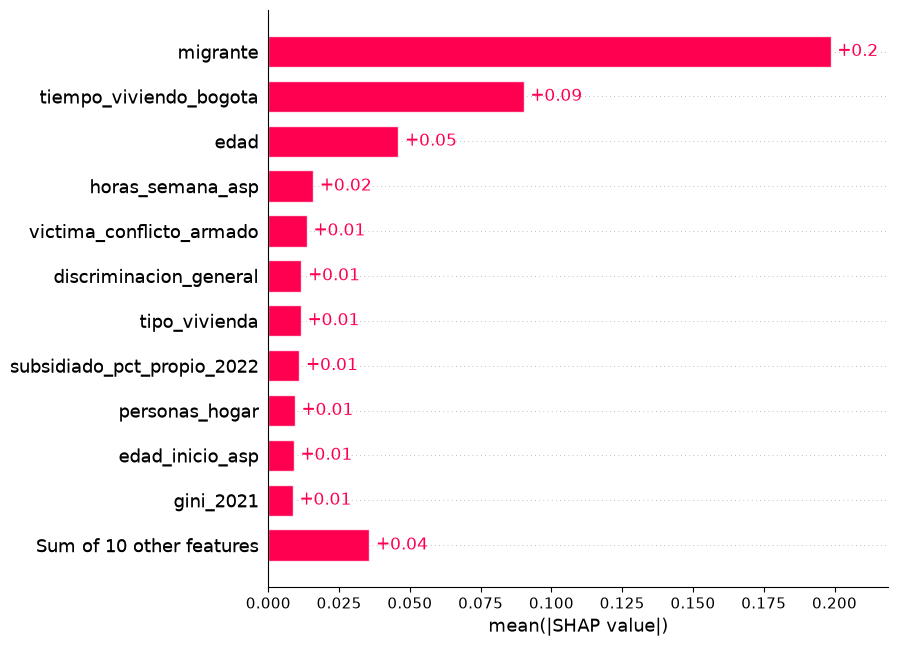

In [25]:
#importancia de cada variable = promedio del aporte en valor absoluto
importancia_shap = pd.Series(np.abs(shap_no_afiliada.values).mean(axis=0),
                             index=X_test.columns).sort_values(ascending=False)
print(importancia_shap.round(3).head(10))

shap.plots.bar(shap_no_afiliada, max_display=12)

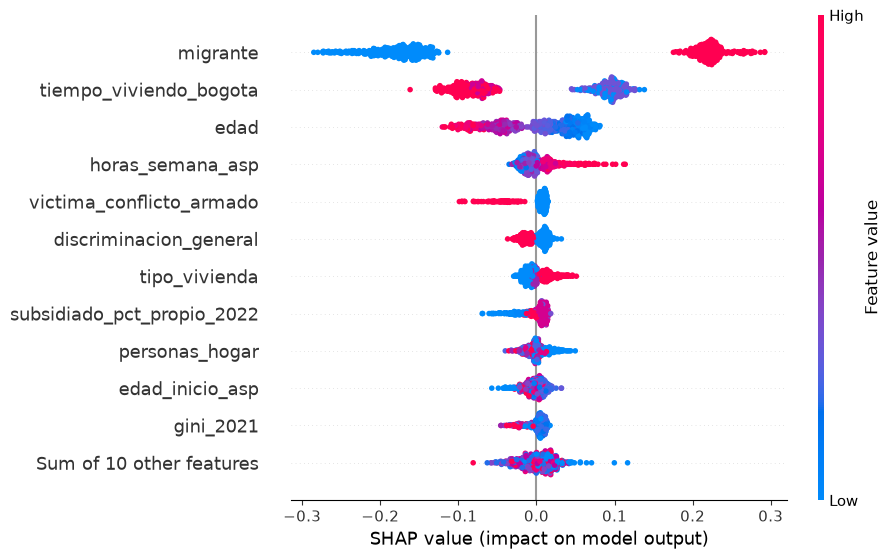

In [26]:
#cada punto es una persona; el color indica el valor de la variable (rojo = alto, azul = bajo)
shap.plots.beeswarm(shap_no_afiliada, max_display=12)

Probabilidad de NO afiliación: 0.98
¿Realmente no afiliada?: Sí


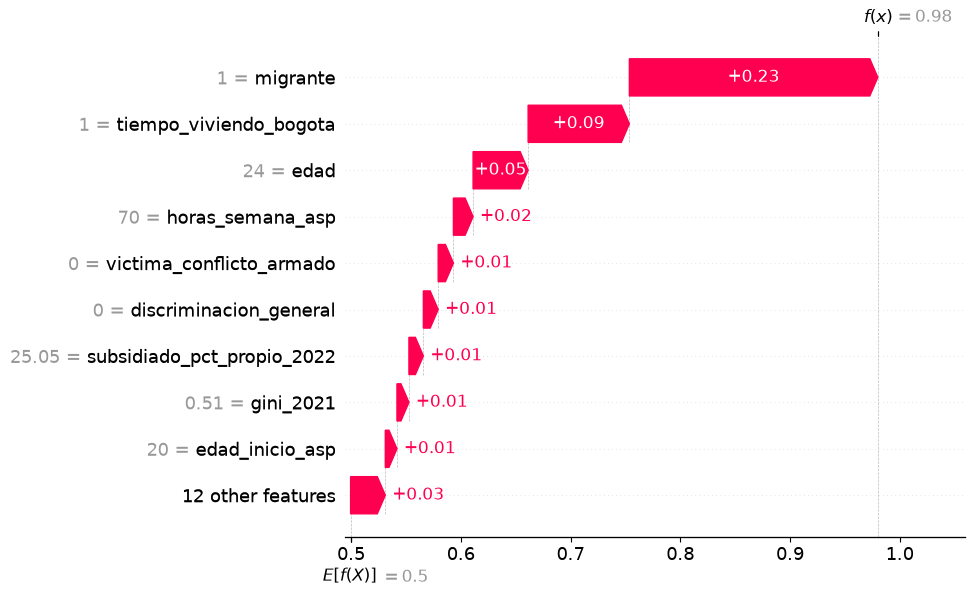

In [27]:
#tomamos a la persona de prueba con MAYOR probabilidad de no afiliación
posicion = int(np.argmax(prob_test))
print("Probabilidad de NO afiliación: %0.2f" % prob_test[posicion])
print("¿Realmente no afiliada?:", "Sí" if y_test.iloc[posicion] == 1 else "No")

shap.plots.waterfall(shap_no_afiliada[posicion], max_display=10)

## Modelo solo con personas migrantes

La condición migratoria domina el modelo. Para ver qué **otros** factores importan, entrenamos un modelo solo con las personas migrantes (quitando la variable `migrante`, que ahí vale 1 para todas).

In [28]:
#filtramos a las migrantes en entrenamiento y prueba, y quitamos la columna migrante
es_migrante_train = X_train["migrante"] == 1
es_migrante_test = X_test["migrante"] == 1

X_mig_train = X_train[es_migrante_train].drop(columns="migrante")
y_mig_train = y_train[es_migrante_train]
X_mig_test = X_test[es_migrante_test].drop(columns="migrante")
y_mig_test = y_test[es_migrante_test]

print("Migrantes en entrenamiento:", len(X_mig_train), " en prueba:", len(X_mig_test))
print("Proporción de NO afiliadas entre migrantes: %0.3f" % y_mig_train.mean())

#Random Forest con los mismos hiperparámetros del modelo final
rf_migrantes = RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                      random_state=42, n_jobs=-1)
auc_cv_mig = cross_validate(rf_migrantes, X_mig_train, y_mig_train,
                            cv=validacion, scoring="roc_auc")["test_score"].mean()
rf_migrantes.fit(X_mig_train, y_mig_train)
auc_test_mig = roc_auc_score(y_mig_test, rf_migrantes.predict_proba(X_mig_test)[:, 1])

print("AUC validación cruzada (migrantes): %0.3f" % auc_cv_mig)
print("AUC prueba (migrantes): %0.3f" % auc_test_mig)

Migrantes en entrenamiento: 1028  en prueba: 255
Proporción de NO afiliadas entre migrantes: 0.871
AUC validación cruzada (migrantes): 0.650
AUC prueba (migrantes): 0.620


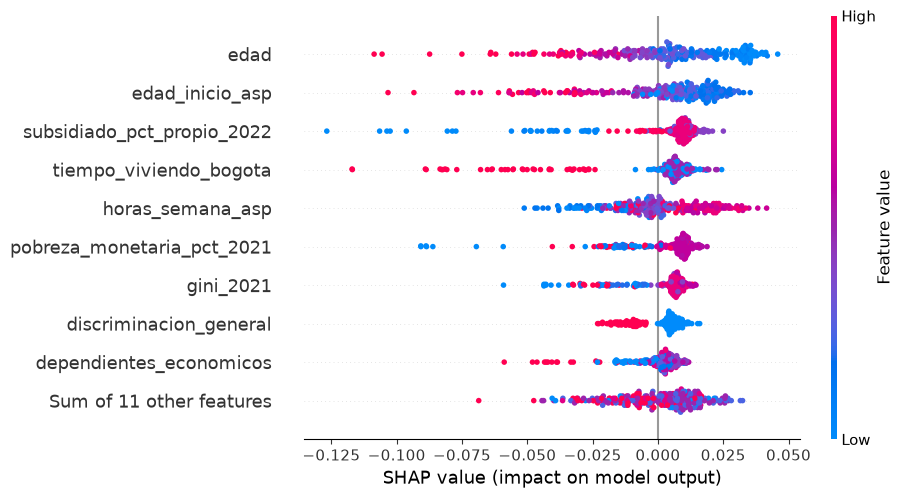

afiliado_seg_social_salud,0,1
tiempo_viviendo_bogota,,
0,0.10,0.90
1,0.12,0.88
2,0.25,0.75
3,0.33,0.67


In [29]:
#qué variables explican la no afiliación DENTRO del grupo de migrantes
shap_migrantes = shap.TreeExplainer(rf_migrantes)(X_mig_test)
if len(shap_migrantes.shape) == 3:
    shap_migrantes = shap_migrantes[:, :, 1]

shap.plots.beeswarm(shap_migrantes, max_display=10)

#tasa de NO afiliación según el tiempo en Bogotá (solo migrantes)
pd.crosstab(X_mig_train["tiempo_viviendo_bogota"], y_mig_train,
            normalize="index").round(2)

**Lo que explica el modelo general:**

- **Ser migrante** es, por mucho, el factor más importante (aporte promedio de 0,20 a la probabilidad, más del doble que el siguiente).
- Le siguen el **tiempo viviendo en Bogotá** (0,09) y la **edad** (0,05): llegar hace poco y ser más joven aumentan el riesgo de no afiliación.
- El resto de las variables, incluidos los indicadores de localidad, aportan muy poco cada una (≤ 0,02).

Esto coincide con la regresión logística y con el perfil "Migrantes de llegada reciente" del clustering: **tres métodos distintos llegan a la misma conclusión**.

**Dentro de las personas migrantes**, la no afiliación es casi generalizada (87 %) y el modelo apenas logra diferenciarlas (AUC ≈ 0,62–0,65). La edad, la edad de inicio y el tiempo en Bogotá ayudan algo: la no afiliación baja de 90 % entre quienes llevan menos de 1 año a 67 % entre quienes llevan más de 10. Pero **las variables de la encuesta no alcanzan a explicar** quién de ellas tiene salud y quién no; probablemente intervienen factores que no medimos (por ejemplo, la situación de regularización migratoria o el conocimiento de la ruta de afiliación).

**Implicación para política pública:** la brecha de afiliación es principalmente un problema de **acceso de la población migrante, en especial la recién llegada**, más que de características individuales dentro de ese grupo. Las intervenciones deberían enfocarse en facilitar la afiliación al llegar, no en focalizar por otros rasgos.

# Modelo para el despliegue en AWS

**Elegimos la regresión logística para el despliegue.** En la evaluación final rindió igual que el Random Forest (AUC 0,882 frente a 0,879, diferencia no significativa), y además:

- Es **interpretable**: cada coeficiente dice cuánto sube o baja el riesgo cada variable.
- Se puede guardar como **unos pocos números** (medias, desviaciones, coeficientes) en un JSON y ejecutar en AWS Lambda **con Python puro**, sin instalar scikit-learn. La función queda liviana, arranca rápido y cuesta menos.

El Random Forest y el análisis SHAP quedan en el informe como respaldo de que un modelo más complejo no aporta más.

In [31]:
#probabilidades de la logística con validación cruzada (solo entrenamiento)
prob_cv_log = cross_val_predict(modelo_logistico, X_train, y_train, cv=validacion,
                                method="predict_proba")[:, 1]

filas = []
for umbral in np.arange(0.30, 0.56, 0.05):
    prediccion = (prob_cv_log >= umbral).astype(int)
    filas.append({"umbral": round(umbral, 2),
                  "recall": recall_score(y_train, prediccion),
                  "precision": precision_score(y_train, prediccion),
                  "f1": f1_score(y_train, prediccion)})
pd.DataFrame(filas).round(3)

,umbral,recall,precision,f1
0,0.30,0.821,0.749,0.784
1,0.35,0.795,0.809,0.802
2,0.40,0.770,0.831,0.799
3,0.45,0.764,0.853,0.806
4,0.50,0.757,0.867,0.808
5,0.55,0.753,0.869,0.807


In [32]:
umbral_logistica = 0.35

#verificación en prueba con ese umbral
prediccion_log = (modelo_logistico.predict_proba(X_test)[:, 1] >= umbral_logistica).astype(int)
print("Prueba con umbral 0,35 -> recall: %0.3f  precisión: %0.3f  F1: %0.3f" %
      (recall_score(y_test, prediccion_log), precision_score(y_test, prediccion_log),
       f1_score(y_test, prediccion_log)))

Prueba con umbral 0,35 -> recall: 0.826  precisión: 0.821  F1: 0.823


In [33]:
#modelo final: misma configuración, pero entrenado con TODAS las personas (entrenamiento + prueba)
modelo_despliegue = clone(modelo_logistico)
modelo_despliegue.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('escalador', ...), ('logistica', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['edad','personas_hogar','dependientes_economicos',..., 'pobreza_monetaria_pct_2021','gini_2021','subsidiado_pct_propio_2022']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [34]:
escalador_d = modelo_despliegue.named_steps["escalador"]
logistica_d = modelo_despliegue.named_steps["logistica"]

#indicadores de cada localidad, para que la Lambda los busque por nombre
tabla_localidades = indicadores.set_index("localidad")

config_modelo = {
    "descripcion": "Regresión logística: probabilidad de NO afiliación a salud",
    "version_sklearn": sklearn.__version__ if "sklearn" in dir() else None,
    "variables": list(X.columns),                    #orden exacto de las 21 variables
    "umbral": umbral_logistica,
    "escalador": {"media": escalador_d.mean_.tolist(),
                  "desviacion": escalador_d.scale_.tolist()},
    "logistica": {"coeficientes": logistica_d.coef_[0].tolist(),
                  "intercepto": float(logistica_d.intercept_[0])},
    "indicadores_localidad": {localidad: fila.to_dict()
                              for localidad, fila in tabla_localidades.iterrows()},
    "metricas_prueba": {"auc": round(roc_auc_score(y_test, modelo_logistico.predict_proba(X_test)[:, 1]), 3),
                        "recall": round(recall_score(y_test, prediccion_log), 3),
                        "precision": round(precision_score(y_test, prediccion_log), 3)}
}

with open("modelos/modelo_afiliacion.json", "w", encoding="utf-8") as archivo:
    json.dump(config_modelo, archivo, ensure_ascii=False, indent=2)
print("Guardado modelos/modelo_afiliacion.json")

Guardado modelos/modelo_afiliacion.json


In [35]:
#probabilidad de NO afiliación usando solo listas y math, como en la Lambda
def probabilidad_no_afiliacion(valores, config):
    esc = config["escalador"]
    log = config["logistica"]

    #1. escalado
    z = [(v - m) / d for v, m, d in zip(valores, esc["media"], esc["desviacion"])]

    #2. combinación lineal: intercepto + suma(coeficiente x valor)
    puntaje = log["intercepto"] + sum(c * v for c, v in zip(log["coeficientes"], z))

    #3. función sigmoide: convierte el puntaje en una probabilidad entre 0 y 1
    return 1 / (1 + math.exp(-puntaje))

#comparamos con scikit-learn para las 2991 personas
prob_manual = np.array([probabilidad_no_afiliacion(fila, config_modelo) for fila in X.values.tolist()])
prob_sklearn = modelo_despliegue.predict_proba(X)[:, 1]
print("Diferencia máxima con scikit-learn:", np.abs(prob_manual - prob_sklearn).max())

Diferencia máxima con scikit-learn: 2.220446049250313e-16


**Modelo desplegado:** regresión logística entrenada con las 2991 personas, umbral 0,35.

- En prueba: AUC 0,88, recall 0,83 y precisión 0,82: detecta a más de 8 de cada 10 personas sin afiliación, y de cada 10 que marca, 8 realmente no están afiliadas.
- Se guardó en `modelos/modelo_afiliacion.json` (unos 4 KB) con los coeficientes, el escalado, el umbral y los indicadores de las 19 localidades.
- La versión en Python puro reproduce exactamente las probabilidades de scikit-learn, así que la Lambda dará los mismos resultados que este notebook.